In [2]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)


In [3]:
# Reading the saved data pickle file
rng = pd.date_range('2019-02-24', periods=661, freq='T')
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)

In [4]:
df["articles"].describe()
df = df.join(df_sentiment)
df[["VIX"]] = df["adj close"].apply(np.int)
df["log_VIX"]=np.log(df["VIX"]/df["VIX"].shift(1))
df[['sentiment']] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(20).mean()

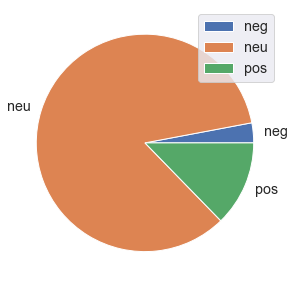

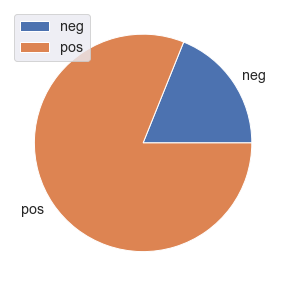

In [10]:
values = [np.sum(df['neg']), np.sum(df['neu']), np.sum(df['pos'])]

plt.figure(figsize=(5, 5))
plt.pie(values,labels=["neg","neu","pos"])
plt.legend()

values = [np.sum(df['neg']), np.sum(df['pos'])]
plt.figure(figsize=(5, 5))
plt.pie(values,labels=["neg","pos"])
plt.legend()
# # df[["neg","neu","pos"]].plot(y='neg', figsize=(5, 5), kind="pie")